# **Lab 4: Filters II**
### RAMZI and RF Filtering
***

**Name**: Andrés Sanchez-Toril

***

#### **Section 1**:  2nd-order RAMZI filter implementation

The following Figure describes the structure of a simplified RAMZI (Ring-Assisted Mach-Zenhder Interferometer) Filter. A simplified RAMZI filter is based on the use of a cascade of rings on each arm of the Mach–Zenhder Interferometer (MZI), thus implementing two all-pass functions on each arm. The total number of rings used gives the order of the filter, as each ring implements a pole-zero pair. In this exercise we are going to implement a 2nd-order simplified RAMZI filter.

<figure> 
    <center>
        <img src="Images/ramzi.png" style="width:40%">
        <figcaption align = "center"> <i> <b> Fig. 1. </b> RAMZI Filter structure implemented with tunable rings </i> </figcaption>
    </center>
</figure>

The FSR (Free Spectral Range) of the rings will be the final FSR of the filter. 
\begin{equation*}
\text{FSR(Hz)} = \dfrac{c_0}{n_{g}L}
\tag{1}
\end{equation*}

**Exercise 1:** Implement the responses $H_{\text{bar}}(f)$ and $H_{\text{cross}}(f)$ using the response of the tunable ring implented in the *Section 2* of the notebook **Filters I**.

\begin{equation*}
H_{\text{bar}}(f) = \dfrac{1}{2} \left[ H_{\text{up}}(f) + H_{\text{down}}(f)\right]
\tag{2}
\end{equation*}

\begin{equation*}
H_{\text{cross}}(f) = \dfrac{1}{2} \left[ H_{\text{up}}(f) - H_{\text{down}}(f)\right]
\tag{3}
\end{equation*}

First, define a callable function of the ring to use it later, as following:


In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
def neff_model():
    # Datos simulados
    wvl_data = np.linspace(1500e-9, 1600e-9, 21)
    
    neff_data = [2.34346, 2.33627, 2.32907, 2.32185, 2.31461, 2.30737,
                 2.30010, 2.29282, 2.28553, 2.27822, 2.27090,
                 2.26356, 2.25620, 2.24883, 2.24145, 2.23405,
                 2.22664, 2.21921, 2.21177, 2.20431, 2.19683]
    
    # Fit
    p = np.poly1d(np.polyfit(wvl_data, neff_data, 6))
    
    return p

p = neff_model()

In [3]:
def ring(wvl,L,phi1,phi2,phi_r):
    """
    This function returns the transfer function of a tunable ring implemented with an MZI:

    Parameters:
    - wvl: Wavelength vector
    - L: Total length of the ring
    - phi1: phase shifter 1 of the MZI
    - phi2: phase shifter 2 of the MZI
    - phi_r: phase shifter of the ring

    Returns:
    - H
    """
    alpha_ring = 0.98
    alpha_MZI = 0.99
    neff = p(wvl)  

    # Propagation constant
    beta = 2 * np.pi * neff / wvl
    tau = beta * L
    
    # MZI phases
    theta = (phi2 - phi1) / 2
    Delta = (phi1 + phi2) / 2

    # Exponentials
    exp_theta = np.exp(1j * theta)
    exp_ring = np.exp(1j * (tau + phi_r))
    
    # Transfer function
    numerator = 1j * alpha_ring * exp_theta * exp_ring - np.sin(theta)
    denominator = 1 - 1j * alpha_ring * exp_theta * exp_ring * np.sin(theta)
    
    H = -1j * np.exp(1j * Delta) * alpha_MZI * (numerator / denominator)

    
    return H

\begin{equation*}
E2 = -je^{j\Delta} \alpha_{\text{MZI}}
\left( \frac{j\alpha_{\text{ring}}e^{j\theta}e^{j(\tau+\phi_r)}-sin\theta}{1-j\alpha_{\text{ring}}e^{j\theta}e^{j(\tau+\phi_r)}sin\theta} \right) E1
%\tag{12}
\end{equation*}

In [4]:
n = 5000 # Number of points
wvl = np.linspace(1549.5e-9, 1550.5e-9, n)
phi1 = 0.8 * np.pi
phi2 = 0.1 * np.pi
r = 0.3e-3 # Radius of the ring
L = 2*np.pi*r # Round-trip length of the ring 
phi_r = 0

Et1 = ring(wvl,L,phi1,phi2,phi_r)
Pt1 = abs(Et1)**2

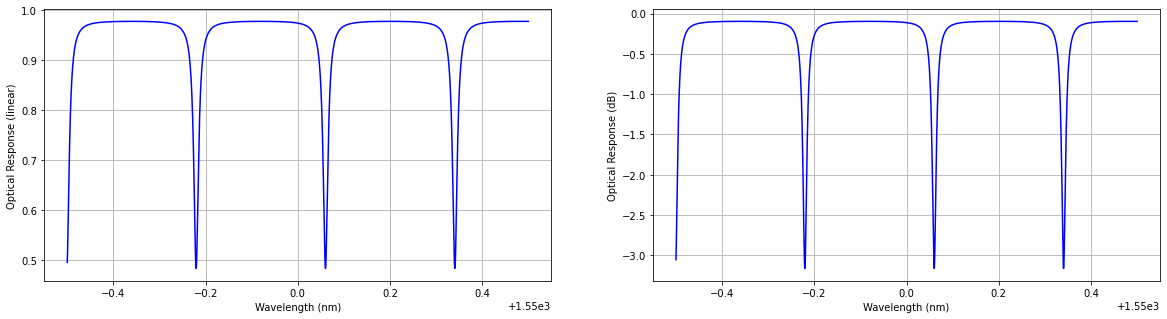

In [5]:
# Plot figures
fig, axs = plt.subplots(1,2,figsize=(20, 5))
# Linear
axs[0].plot(wvl*1e9, Pt1, 'b')
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
axs[0].grid(True)
# Logarithmic
axs[1].plot(wvl*1e9, 10*np.log10(Pt1), 'b')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')
axs[1].grid(True)



Then, create both rings and the responses of the bar and cross outputs, and show the response in dB. Use the following parameters for the phase shifters, corresponding to a Chebyshev Type II filter with 20 GHz bandwidth:

In [6]:
wvl_data = np.linspace(1500e-9, 1600e-9, 21)
neff_data = [2.34346, 2.33627, 2.32907, 2.32185, 2.31461, 2.30737,
            2.30010, 2.29282, 2.28553, 2.27822, 2.27090,
            2.26356, 2.25620, 2.24883, 2.24145, 2.23405,
            2.22664, 2.21921, 2.21177, 2.20431, 2.19683]

slope_local = np.gradient(neff_data, wvl_data)
slope_local = np.mean(slope_local)
#print(slope_local)
n_g = neff_data[10] - 1550e-9*slope_local
print(n_g)

4.543716666666667


In [7]:
import numpy as np
from matplotlib import pyplot as plt

# Parameters
neff = 4.18
FSR = 40e9 
wvl0 = 1550e-9

c0 = 3e8
n_g = 4.54
L = c0/(FSR*n_g)

# Ring 1
phi1_1 = 1.580195956110028
phi2_1 = 0
phi_r1 = 4.553097547147326 

# Ring 2
phi1_2 = 1.580195956110028
phi2_2 = 0
phi_r2 = 3.8169922086647525 

n = 5000 # Number of points
wvl = np.linspace(1549.5e-9, 1550.5e-9, n)


In [8]:
Eup = ring(wvl,L,phi1_1,phi2_1,phi_r1)
Edown = ring(wvl,L,phi1_2,phi2_2,phi_r2)

H_bar = (Eup + Edown)/2
H_cross = (Eup - Edown)/2

P_bar = abs(H_bar)**2
P_cross = abs(H_cross)**2

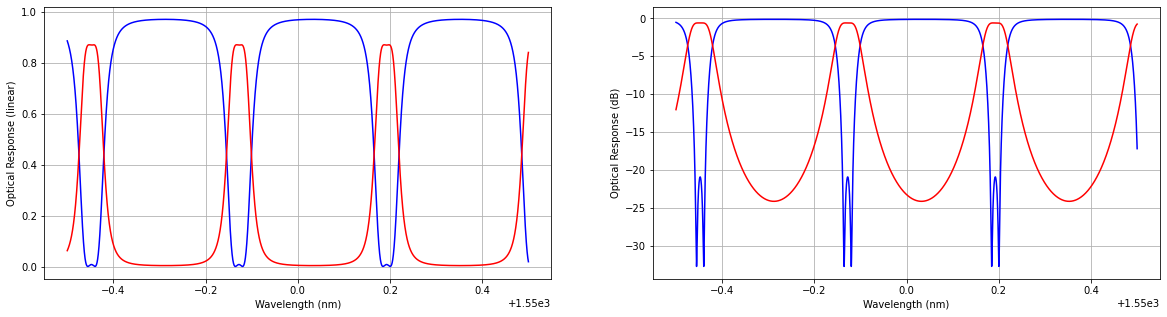

In [9]:
lambda1 = 1550e-9
lambda2 = lambda1 + 0.4e-9

# Plot figures
fig, axs = plt.subplots(1,2,figsize=(20, 5))
# Linear
axs[0].plot(wvl*1e9, P_bar, 'b')
axs[0].plot(wvl*1e9, P_cross, 'r')
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
axs[0].grid(True)
# axs[0].axvline(lambda1*1e9, color='k', linestyle='--')
# axs[0].axvline(lambda2*1e9, color='k', linestyle='--')
# Logarithmic
axs[1].plot(wvl*1e9, 10*np.log10(P_bar), 'b')
axs[1].plot(wvl*1e9, 10*np.log10(P_cross), 'r')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')
axs[1].grid(True)

**Exercise 2**: Now we want to move the central wavelength of the bar response half the FSR of the filter. Change the corresponding parameters to do that and plot the result.

In [10]:
import numpy as np
from matplotlib import pyplot as plt

# Parameters
neff = 4.18
L = 0.0016519823788546256 
wvl0 = 1550e-9

# Ring 1
phi1_1 = 1.580195956110028 
phi2_1 = 0
phi_r1 = 4.553097547147326 + np.pi

# Ring 2
phi1_2 = 1.580195956110028
phi2_2 = 0
phi_r2 = 3.8169922086647525 + np.pi   

n = 5000 # Number of points
wvl = np.linspace(1549.5e-9, 1550.5e-9, n)

In [11]:
Eup = ring(wvl,L,phi1_1,phi2_1,phi_r1)
Edown = ring(wvl,L,phi1_2,phi2_2,phi_r2)

H_bar = (Eup + Edown)/2
H_cross = (Eup - Edown)/2

P_bar_2 = abs(H_bar)**2
P_cross_2 = abs(H_cross)**2

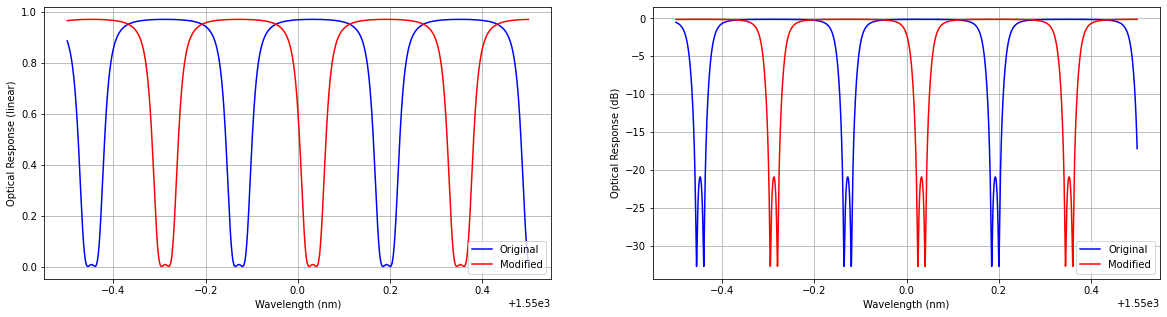

In [12]:
# Plot figures
fig, axs = plt.subplots(1,2,figsize=(20, 5))
# Linear
axs[0].plot(wvl*1e9, P_bar, 'b', label='Original')
axs[0].plot(wvl*1e9, P_bar_2, 'r', label='Modified')
axs[0].set(xlabel='Wavelength (nm)', ylabel='Optical Response (linear)')
axs[0].legend()
axs[0].grid(True)
# Logarithmic
axs[1].plot(wvl*1e9, 10*np.log10(P_bar), 'b', label='Original')
axs[1].plot(wvl*1e9, 10*np.log10(P_bar_2), 'r', label='Modified')
axs[1].set(xlabel='Wavelength (nm)', ylabel='Optical Response (dB)')
axs[1].legend()
axs[1].grid(True)

***
#### **Section 2**:  RF Filtering

<figure> 
    <center>
        <img src="Images/link.png" style="width:80%">
        <figcaption align = "center"> <i> <b> Fig. 2. </b> Microwave Photonic Link </i> </figcaption>
    </center>
</figure>

Figure 2 shows a microwave photonic link divided in 4 parts. The MZM Dual-Drive has to generate a single-sideband modulation for a set of frequencies. Then, the RAMZI filter response will be set in that sideband and the output response will be photodetected. The final objective is to see the frequency response of the RAMZI filter after photodetection. For that, we will follow the next steps: 

**Exercise 3**: Generate the laser output response $E_{\text{in}}$ at 1550 nm, with an input power of 20 dBm, knowing that

\begin{equation*}
E_{\text{in}}(t)= \sqrt{P_{\text{in}}} e^{j \omega_c t}
\tag{4}
\end{equation*}

\begin{equation*}
P(\text{W}) = 10^{-3} \cdot 10^{P_{\text{dBm}}/10}
\end{equation*}


\begin{equation*}
\omega = 2\pi f = 2\pi \frac{c}{\lambda}
\end{equation*}

In [13]:
# Parameters
# Insert here corresponding parameters as input power, angular frequency...

# Input power
Pin_dBm = 20
Pin = 1e-3 * 10**(Pin_dBm/10)

# Optical frequency
c = 3e8
lambda0 = 1550e-9
f_c = c / lambda0
wc = 2 * np.pi * f_c

# Time array generation

fs = 200e9        # suficiente para cubrir hasta 20 GHz
Ts = 1/fs
t = np.arange(0, 30e-9, Ts)

# Original ------
# Nf = 8 # Frequency sampling
# Nt = 30 # Time sampling
# fs = Nf*f_c
# Ts = 1/fs
# t = np.arange(0, Nt*1e-9, Ts)

# Laser output response

Ein = np.sqrt(Pin) * np.exp(1j * wc * t)


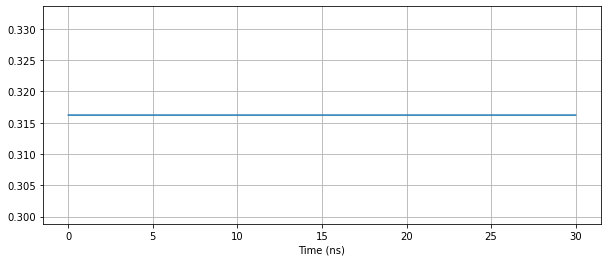

In [14]:
plt.figure(figsize=(10,4))
plt.plot(t*1e9, np.abs(Ein))
plt.xlabel("Time (ns)")
plt.grid()

**Exercise 4**: Modulate the MZM with a two tone signal in both arms and represent the optical output response (in dBm). 

In order to operate the intensity modulator and obtain the desired light modulation, one must apply two well suited electrical voltages to the modulator: a modulation voltage $V_{\text{in}} (t)$ (also called RF voltage) and a DC voltage (also called bias voltage). Radio-frequency signals for upper and lower arm are defined as following:

\begin{equation*}
V_{\text{in}} (t) = V_{\text{RF}} \left[\cos(\omega_1 t + \phi_{\text{RF}}) + \cos(\omega_1 t + \phi_{\text{RF}}) \right],
\tag{5}
\end{equation*}

where $\phi_{\text{RF}}) = 0$ for upper arm, and $\phi_{\text{RF}})=\pi$ for lower arm of the MZM, and $V_{\text{RF}} = \sqrt{2P_{\text{RF}}R}$ ($R=50 \Omega$). Use $f_1 = 5$ GHz and $f_2 = 20$ GHz

Output field of the MZM is defined as:

\begin{equation*}
E_{\text{out}}(t) = \dfrac{E_{\text{in}}(t)}{2} \left[ e^{j\dfrac{\pi V_{\text{in}}^{\text{up}}(t)}{V_{\pi}}} e^{j\phi_{\text{DC}}} + e^{j\dfrac{\pi V_{\text{in}}^{\text{down}}(t)}{V_{\pi}}} \right],
\tag{6}
\end{equation*}

where the halfwave voltage, $V_{\pi}$, is defined as the difference between the applied voltage at which the signals in each branch of the MZM are in phase and the applied voltage at which the signals are $\pi$ radians out of phase. For this exercise, use $V_{\pi}=5$. 


The modulator operating point ($\phi_{\text{DC}}$) is the point on the transfer curve around which the modulation signal is applied. In the following images, it appears as $V_{\text{bias}}$ (but don't confuse it with the previous parameter $V_{\pi}$, we are going to use phase instead of voltage for the bias point).
<figure> 
    <center>
        <img src="Images/mzm1.png" style="width:30%">
        <figcaption align = "center"> <i> <b> Fig. 3. </b> Transfer function of an intensity Mach-Zehnder modulator. </i> </figcaption>
    </center>
</figure>

It has to be selected depending on the targeted application. We can give the following examples:

<figure> 
    <center>
        <img src="Images/mzm2.png" style="width:60%">
        <figcaption align = "center"> <i> <b> Fig. 4. </b> Examples of diferent signal modulations using a MZM. </i> </figcaption>
    </center>
</figure>

For this exercise we are modulating an analog signal, so we should use the most linear regime $\phi_{\text{DC}}= \pi/2$.

In [15]:
# Definicion de V_RF
#---------------------------------------------------------
R = 50
P_RF = 0.01  # 10 mW RF
V_RF = np.sqrt(2 * P_RF * R)

# Definicion de los voltajes de modulacion a las entradas
#---------------------------------------------------------
f1 = 5e9
f2 = 20e9
V_up = V_RF*(np.cos(2*np.pi*f1*t) + np.cos(2*np.pi*f2*t))
V_down = V_RF*(np.cos(2*np.pi*f1*t + np.pi) + np.cos(2*np.pi*f2*t + np.pi)) 
# Recordar que cos(x + pi) = -cos(x)

# Definicion de Ein, eliminar la exponencial compleja para evitar desplazamientos
# en frecuencia
Ein = np.sqrt(Pin)
# Ein = np.sqrt(Pin) * np.exp(1j * wc * t)

# Definicion del campo de salida
#---------------------------------------------------------
Vpi = 5
phi_DC = np.pi/2
E_out = (Ein/2)*(
    np.exp(1j*(np.pi*V_up/Vpi + phi_DC)) +
    np.exp(1j*(np.pi*V_down/Vpi))
)

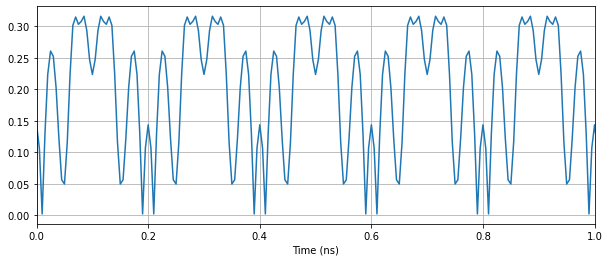

In [16]:
plt.figure(figsize=(10,4))
plt.plot(t*1e9, np.abs(E_out))
plt.xlabel("Time (ns)")
plt.xlim(0, 1)
plt.grid()

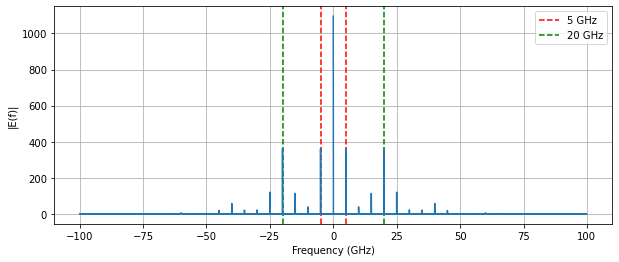

In [17]:
E = E_out

# FFT
E_f = np.fft.fft(E)
N = len(t)
freq = np.fft.fftfreq(N, d=Ts)



plt.figure(figsize=(10,4))
plt.xlabel("Frequency (GHz)")
plt.ylabel("|E(f)|")
plt.axvline(x=5, color='r', linestyle='--', label='5 GHz')
plt.axvline(x=-5, color='r', linestyle='--')
plt.axvline(x=20, color='g', linestyle='--', label='20 GHz')
plt.axvline(x=-20, color='g', linestyle='--')
plt.plot(freq / 1e9, np.abs(E_f))
plt.legend()
plt.grid()

In [18]:
# Definicion de V_RF
#---------------------------------------------------------
R = 50
P_RF = 0.01  # 10 mW RF
V_RF = np.sqrt(2 * P_RF * R)

# Definicion de los voltajes de modulacion a las entradas
#---------------------------------------------------------
f1 = 5e9
f2 = 20e9
V_up = V_RF*(np.cos(2*np.pi*f1*t) + np.cos(2*np.pi*f2*t))
V_down = V_RF*(np.cos(2*np.pi*f1*t + np.pi) + np.cos(2*np.pi*f2*t + np.pi)) 
# Recordar que cos(x + pi) = -cos(x)

# Definicion de Ein, eliminar la exponencial compleja para evitar desplazamientos
# en frecuencia
# Ein = np.sqrt(Pin)
Ein = np.sqrt(Pin) * np.exp(1j * wc * t)

# Definicion del campo de salida
#---------------------------------------------------------
Vpi = 5
phi_DC = np.pi/2
E_out = (Ein/2)*(
    np.exp(1j*(np.pi*V_up/Vpi + phi_DC)) +
    np.exp(1j*(np.pi*V_down/Vpi))
)

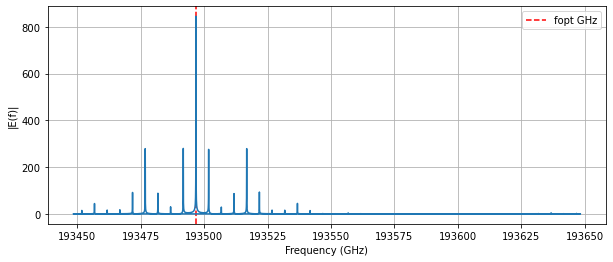

In [19]:
E = E_out

# FFT
E_f = np.fft.fft(E)
N = len(t)
freq = np.fft.fftfreq(N, d=Ts)
f_opt = f_c + freq

E_mag = np.abs(E_f)
idx_peak = np.argmax(E_mag)
f_peak = f_opt[idx_peak]

# Magnitud
plt.figure(figsize=(10,4))
plt.xlabel("Frequency (GHz)")
plt.ylabel("|E(f)|")
plt.axvline(x=f_peak/1e9, color='r', linestyle='--', label='fopt GHz')
plt.plot(f_opt / 1e9, np.abs(E_f))
plt.legend()
plt.grid()

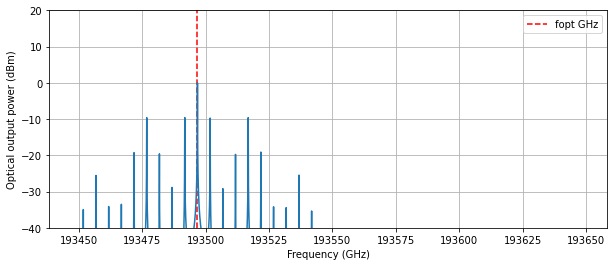

In [20]:
from numpy.fft import fft, fftshift

# Output field of the MZM in frequency
E_f = fftshift(fft(E_out))

# Frecuencia
l = len(t)
f = np.linspace(-fs/2, fs/2, l)

# Frecuencia óptica
f_opt = f_c + f

# Potencia
P = np.abs(E_f)**2
P = P / np.max(P)

# dBm
P_dBm = 10*np.log10(P + 1e-12)

# Plot
plt.figure(figsize=(10,4))
plt.axvline(x=f_peak/1e9, color='r', linestyle='--', label='fopt GHz')
plt.plot(f_opt/1e9, P_dBm)
#plt.xlim(f_c/1e9-70, f_c/1e9+70)
plt.ylim(-40, 20)
plt.xlabel('Frequency (GHz)')
plt.ylabel('Optical output power (dBm)')
plt.legend()
plt.grid()

**Exercise 5**: Plot the last result changing the x-axis to wavelength instead of frequency.

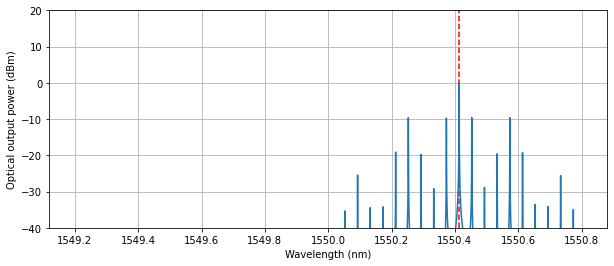

In [21]:
lambda_opt = c / f_opt

idx_peak = np.argmax(P_dBm)
l_peak = lambda_opt[idx_peak]

plt.figure(figsize=(10,4))
plt.axvline(x=l_peak*1e9, color='r', linestyle='--', label='lambda_opt nm')
plt.plot(lambda_opt*1e9, P_dBm)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Optical output power (dBm)')
plt.ylim(-40, 20)
plt.grid()

**Exercise 6**: Use the RAMZI filter of the section 1 (change the wavelength vector to the new one) for filtering optical carrier and the 5 GHz sidebands, and eliminate the 20 GHz signal.

In [22]:
# Use the full wavelength vector 
wvl_full = np.concatenate((np.flip(-wvl),[1e-12],wvl)) 

In [23]:
# Parameters
neff = 4.18
FSR = 40e9 
wvl0 = l_peak

c0 = 3e8
n_g = 4.54
L = c0/(FSR*n_g)

# Ring 1
phi1_1 = 1.580195956110028
phi2_1 = 0
phi_r1 = 4.553097547147326 + 1.1*np.pi/3

# Ring 2
phi1_2 = 1.580195956110028
phi2_2 = 0
phi_r2 = 3.8169922086647525 + 1.1*np.pi/3

wvl = lambda_opt

In [24]:
Eup = ring(wvl,L,phi1_1,phi2_1,phi_r1)
Edown = ring(wvl,L,phi1_2,phi2_2,phi_r2)

H_bar = (Eup + Edown)/2
H_cross = (Eup - Edown)/2

P_bar = abs(H_bar)**2
P_cross = abs(H_cross)**2

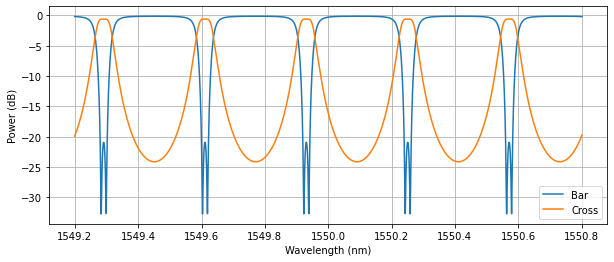

In [25]:
plt.figure(figsize=(10,4))
plt.plot(wvl*1e9, 10*np.log10(P_bar + 1e-12), label="Bar")
plt.plot(wvl*1e9, 10*np.log10(P_cross + 1e-12), label="Cross")

plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dB)")
plt.legend()
plt.grid()

No handles with labels found to put in legend.


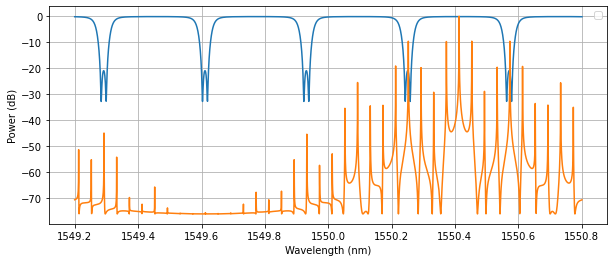

In [26]:
plt.figure(figsize=(10,4))
plt.plot(wvl*1e9, 10*np.log10(P_bar + 1e-12))
plt.plot(lambda_opt*1e9, P_dBm)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dB)")
plt.legend()
plt.grid()

In [27]:
E_filtered = E_f * H_bar

In [28]:
P_filtered = np.abs(E_filtered)**2
P_filtered = P_filtered / np.max(P_filtered)
P_filtered_dBm = 10*np.log10(P_filtered + 1e-12)

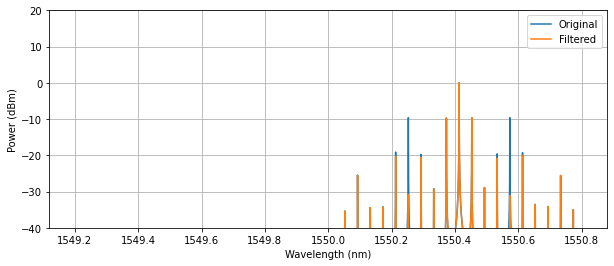

In [29]:
plt.figure(figsize=(10,4))
plt.plot(lambda_opt*1e9, P_dBm, label="Original")
plt.plot(lambda_opt*1e9, P_filtered_dBm, label="Filtered")
plt.ylim(-40, 20)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Power (dBm)")
plt.legend()
plt.grid()

**Exercise 7**: Represent the photodetected response before and after filtering.

\begin{equation*}
I_{\text{PD}}(t)= R_{\text{PD}} R |E_{\text{out}(t)}|^2
\tag{7}
\end{equation*}

Where $R_{\text{PD}}$ is the responsivity of the pho

In [30]:
from numpy.fft import ifft, ifftshift

E_time = ifft(ifftshift(E_f))
E_filtered_time = ifft(ifftshift(E_filtered))

R_pd = 1  

I_pd = R_pd * np.abs(E_time)**2
I_pd_filtered = R_pd * np.abs(E_filtered_time)**2

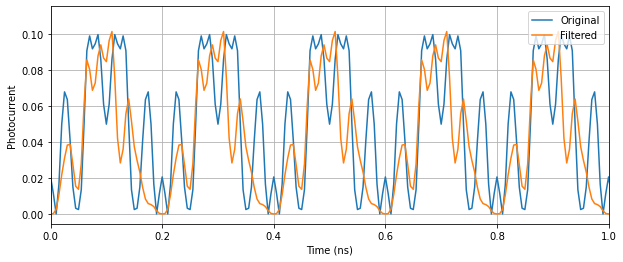

In [31]:
plt.figure(figsize=(10,4))
plt.plot(t*1e9, I_pd, label="Original")
plt.plot(t*1e9, I_pd_filtered, label="Filtered")

plt.xlabel("Time (ns)")
plt.ylabel("Photocurrent")
plt.xlim(0, 1)

plt.legend(loc='upper right')
plt.grid()

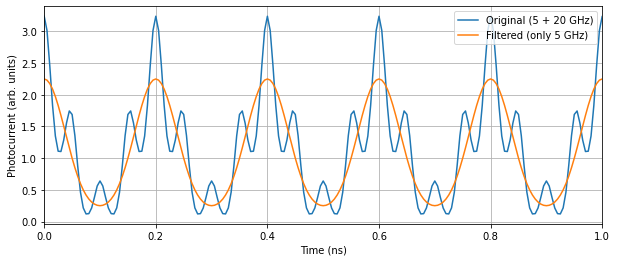

In [32]:
fs = 200e9

f1 = 5e9
f2 = 20e9

# Señal original (con 5 GHz + 20 GHz)
I_original = (1 
              + 0.5*np.cos(2*np.pi*f1*t) 
              + 0.3*np.cos(2*np.pi*f2*t))**2

# Señal filtrada ideal (solo 5 GHz)
I_filtered = (1 
              + 0.5*np.cos(2*np.pi*f1*t))**2

plt.figure(figsize=(10,4))
plt.plot(t*1e9, I_original, label="Original (5 + 20 GHz)")
plt.plot(t*1e9, I_filtered, label="Filtered (only 5 GHz)")

plt.xlabel("Time (ns)")
plt.ylabel("Photocurrent (arb. units)")
plt.xlim(0, 1)

plt.legend(loc='upper right')
plt.grid()

plt.show()